In [26]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr
from scipy.stats import spearmanr
sns.set_style("whitegrid")


# ¿ De qué va este EDA?
Spotify obtiene indicadores mediante algoritmos de análisis de audio que procesan las características acústicas de cada canción, como el ritmo, la intensidad, el tempo, la estructura sonora y las propiedades espectrales. A partir de estos parámetros, sus modelos estiman diferentes atributos musicales y los transforman en valores normalizados entre 0 y 1. Estos valores no proceden de votaciones de los usuarios ni de valoraciones subjetivas, sino de modelos computacionales desarrollados por Spotify. Cada indicador mide una dimensión diferente: por ejemplo, Energy estima la intensidad y actividad percibida, Danceability la adecuación rítmica para bailar y Valence el carácter emocional positivo o negativo de la música.

Basdonos en ellos  vamos analizar un CSV con 15.000 hits. Analizaremos la evolución de la música en clave sociohistórica, haciendo un mix entre ciencia de datos y estudios culturales.

Nuestro CVS tiene 15000 registros, que empiezan con hits desde 1923. Sin embargo tras actor el marco temporal(1970-2015) nos quedamos en algo más de 10.000.

| Variable         | Rango habitual    | Significado                                       |
| ---------------- | ----------------- | ------------------------------------------------- |
| Danceability     | 0 – 1             | Facilidad para bailar.                            |
| Energy           | 0 – 1             | Intensidad y actividad de la canción.             |
| Loudness         | -60 – 0 dB aprox. | Volumen percibido de la grabación.                |
| Speechiness      | 0 – 1             | Presencia de palabras habladas.                   |
| Acousticness     | 0 – 1             | Probabilidad de que sea acústica.                 |
| Instrumentalness | 0 – 1             | Probabilidad de que no tenga voces.               |
| Liveness         | 0 – 1             | Probabilidad de que sea una grabación en directo. |
| Valence          | 0 – 1             | Positividad emocional percibida.                  |
| Tempo            | BPM               | Velocidad de la canción.                          |
| Duration         | Milisegundos      | Duración original de la canción.                  



# Tratamiento de los datos
El tratamiento de los datos requiere muy pocos cambios. En primer lugar, eliminamos todas las observaciones correspondientes a años que quedan fuera del periodo de estudio.

En segundo lugar, creamos una nueva variable categórica que agrupa los años en diferentes intervalos temporales, con el objetivo de facilitar el análisis y la comparación entre periodos.

También creamos la variable Genre2, en la que fusionamos los géneros Pop y Today. Esta decisión se basa en que las canciones clasificadas como Pop corresponden a años anteriores a 2000, mientras que las clasificadas como Today comienzan en 2002. Por tanto, entendemos que Today representa una continuación del género Pop. Asimismo, mantenemos el género Metal como una categoría independiente, ya que ambos géneros (Pop y Metal) son los que cuentan con un mayor número de registros. El resto de los géneros se agrupan en una única categoría denominada Resto de géneros.

De manera similar, creamos la variable Genre3, con el objetivo de aislar el género Country y facilitar su análisis específico.

Por último, multiplicamos por 100 las variables obtenidas a través de la API de Spotify, con el fin de facilitar su interpretación y mejorar la legibilidad de los resultados.

## Variables del dataset tras la limpieza

### Información general

- **Número de registros:** 10.104
- **Número de variables:** 21

### Descripción de las variables

| Variable | Tipo | Descripción |
|---|---|---|
| `Track` | str | Nombre de la canción |
| `Artist` | str | Artista |
| `Year` | int64 | Año de lanzamiento |
| `Duration` | float64 | Duración de la canción |
| `Time_Signature` | int64 | Compás musical |
| `Danceability` | float64 | Facilidad para bailar |
| `Energy` | float64 | Intensidad y energía de la canción |
| `Key` | int64 | Tonalidad musical |
| `Loudness` | float64 | Volumen medio en decibelios |
| `Mode` | int64 | Modalidad musical (mayor o menor) |
| `Speechiness` | float64 | Presencia de palabras habladas |
| `Acousticness` | float64 | Grado de carácter acústico |
| `Instrumentalness` | float64 | Presencia de contenido instrumental |
| `Liveness` | float64 | Probabilidad de que sea una grabación en directo |
| `Valence` | float64 | Positividad emocional de la canción |
| `Tempo` | float64 | Velocidad musical en BPM |
| `Popularity` | int64 | Popularidad de la canción |
| `Genre` | str | Género musical |
| `Yearcat` | category | Clasificación categórica del año |
| `Genre2` | str | Segunda clasificación del género |
| `Genre3` | str | Tercera clasificación del género |

### Conclusión

El dataset resultante presenta una estructura de 10.104 observaciones y 21 variables, sin valores ausentes. Incluye información sobre canciones y artistas, características musicales, popularidad, año de lanzamiento y clasificación por géneros musicales.

Esta estructura permite realizar análisis exploratorios y estudiar posibles relaciones entre las características musicales, la popularidad y la evolución de los géneros a lo largo del tiempo.

In [27]:
#Cargar datos
df = pd.read_csv(r"C:\Users\Iker\Documents\Bootcamp\EDA_Iker_OK\EDA_Iker\ClassicHit.csv")
df = df[df["Year"] > 1970]
df = df[df["Year"] < 2015]

df["Yearcat"] = pd.cut(
    df["Year"],
    bins=[1969, 1979, 1989, 1999, 2015],
    labels=["1970-1979", "1980-1989", "1990-1999", "2000-2015"]
)
df["Genre2"] = np.select(
    [
        df["Genre"] == "Metal",
        df["Genre"].isin(["Pop", "Today"]),        
    ],
    [
        "Metal",
        "Pop/Today",
    ],
    default="Resto de géneros"
)
df["Duration"] = (df["Duration"]/1000) /60


df["Valence"] = df["Valence"] *100
df["Energy"] = df["Energy"] *100
df["Danceability"] = df["Danceability"] *100
df["Speechiness"] = df["Speechiness"] *100
df["Acousticness"] = df["Acousticness"] *100
df["Instrumentalness"] = df["Instrumentalness"] *100
df["Liveness"] = df["Liveness"] *100



medianas1 = df.groupby("Genre")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()
medianas2 = df.groupby("Key")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()
medianas3 = df.groupby("Time_Signature")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()
medianas4 = df.groupby("Genre")[["Mode"]].mean()

variablesmat = ["Year","Loudness","Valence","Energy","Acousticness","Danceability","Tempo","Instrumentalness","Speechiness","Popularity"]
corr = df[variablesmat].corr("spearman")

df["Genre3"] = np.select(
    [
        df["Genre"] == "Country"


    
    ],
    [
        "Country"
      

    ],
    default="Resto de géneros"
)

df.info()

<class 'pandas.DataFrame'>
Index: 10104 entries, 0 to 15149
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Track             10104 non-null  str     
 1   Artist            10104 non-null  str     
 2   Year              10104 non-null  int64   
 3   Duration          10104 non-null  float64 
 4   Time_Signature    10104 non-null  int64   
 5   Danceability      10104 non-null  float64 
 6   Energy            10104 non-null  float64 
 7   Key               10104 non-null  int64   
 8   Loudness          10104 non-null  float64 
 9   Mode              10104 non-null  int64   
 10  Speechiness       10104 non-null  float64 
 11  Acousticness      10104 non-null  float64 
 12  Instrumentalness  10104 non-null  float64 
 13  Liveness          10104 non-null  float64 
 14  Valence           10104 non-null  float64 
 15  Tempo             10104 non-null  float64 
 16  Popularity        10104 non-null  int6

# Hipotesis
### H1. La clave y el modo de las canciones no afecta a los valores de la API de spotify.
### H2. El compás afecta ligeramante a los valores del API de spoty.
### H3. En el periodo 1975-2015 la música ha ganado volumen. 
### H4. En el periodo 1975-2015 la música ha perdido positividad.
### H5. En el periodo 1975-2015 la música ha ganado energía.
### H6. Estos cambios se ven con mas fuerza en el metal


# Primeros analísis descriptivos

In [28]:
### Funciones

def medianas(medianas,titulo):
    plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
    sns.heatmap(
        medianas,
        annot=True,
        cmap= "rocket_r",
        fmt='.2f',
        linewidths=0,
        vmin= 0,
        vmax=100,
        center=50
)
    plt.title(titulo)
    plt.tight_layout()
    plt.show()
    return 

def mediasmodo(medianas):
    plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
    sns.heatmap(
        medianas,
        annot=True,
        cmap= "rocket_r",
        fmt='.2f',
        linewidths=0,
        vmin= 0,
        vmax=1,
        center=0.5
)
    plt.title("Medias de modo según género")
    plt.tight_layout()
    plt.show()

    return 

### variables

medianas1 = df.groupby("Genre")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()
medianas2 = df.groupby("Key")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()
medianas3 = df.groupby("Time_Signature")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()
medianas4 = df.groupby("Genre")[["Mode"]].mean()
medianas5= df.groupby("Mode")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()

Si observamos las medianas de los diferentes atributos por género musical, podemos constatar que existen diferencias significativas entre ellos. En géneros como el EDM, el Gospel o el Metal, la mitad de las canciones presentan un *valence* inferior a 50. Por el contrario, en géneros como el Disco, el Funk o el Ska, la mitad de las canciones superan este valor y se sitúan por encima de 70.

Este primer análisis nos permite observar que atributos como la verbalidad (*speechiness*) o la instrumentalidad (*instrumentalness*) están muy condicionados por géneros especifiocs. Por su parte, el atributo *liveness* presenta una variabilidad muy reducida. Por estos motivos, consideramos que estas tres variables tienen un interés limitado para el análisis posterior.

En cuanto a la tonalidad (*key*), se observa una variabilidad prácticamente nula en relación con los atributos de las canciones. Dado que esta variable parece aportar poca información relevante, se ha decidido no profundizar en la correspondencia entre cada valor numérico y su respectiva nota musical.

Sin embargo, el compás (*time signature*) presenta resultados diferentes. Las canciones cuyo compás es 4 tienden a mostrar valores más elevados de *valence*, *energy* y *danceability*. Este valor corresponde al compás de 4/4, el más habitual en la música popular.

Por otro lado, aunque pueda resultar sorprendente, el modo (*mode*) no parece afectar de forma significativa a la distribución de las medianas de los principales atributos musicales.

No obstante, aunque el modo no es una variable numérica continua, está codificado de forma binaria: 0 corresponde al modo menor y 1 al modo mayor. Esta codificación permite calcular su media para cada género musical. De este modo, podemos aproximarnos a la proporción de canciones que utilizan el modo mayor en cada género. Los resultados muestran que géneros como el Country, el Gospel o el Ska presentan una mayor tendencia a utilizar el modo mayor.

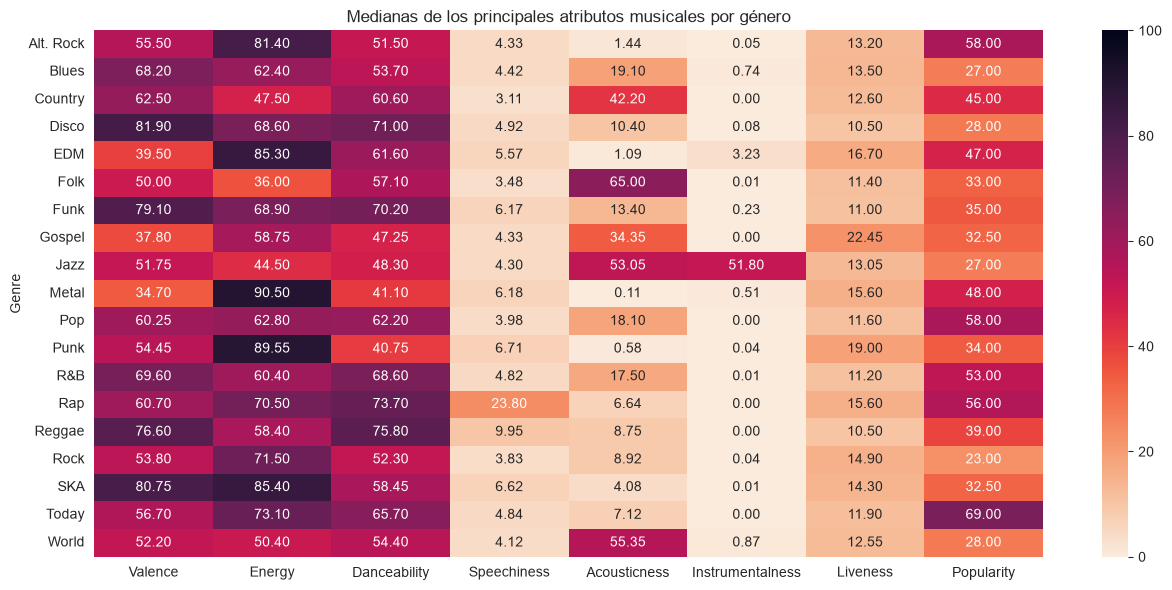

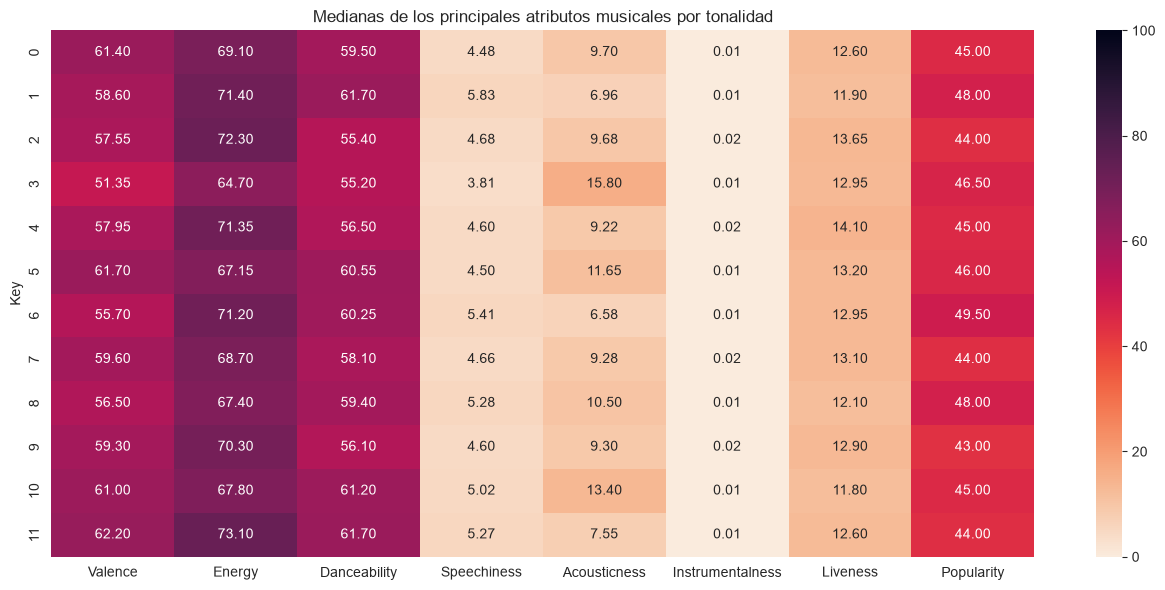

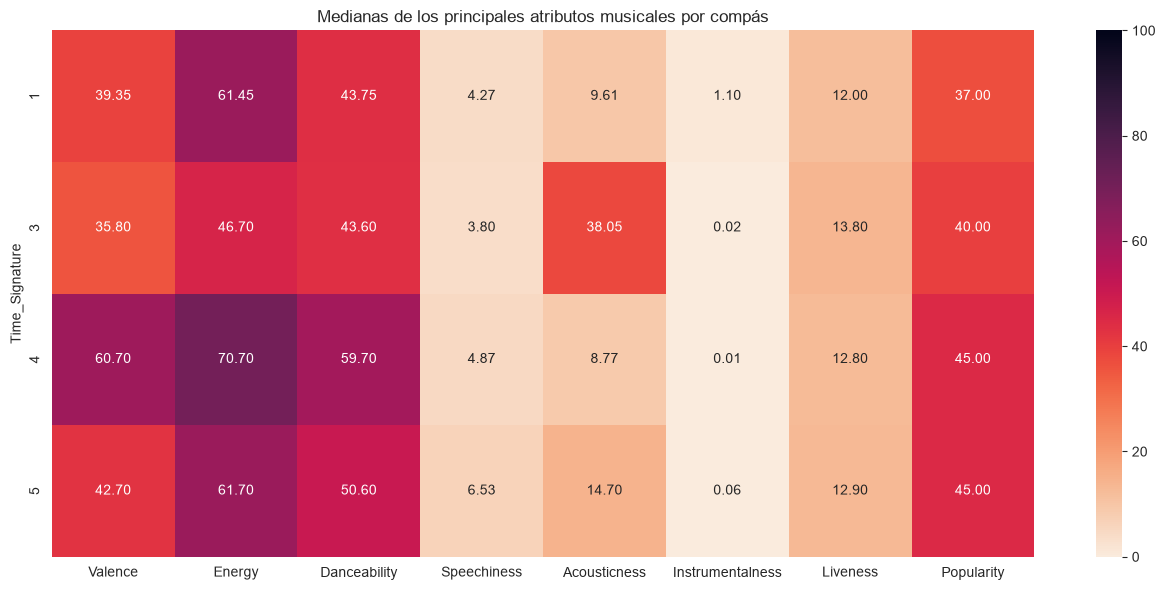

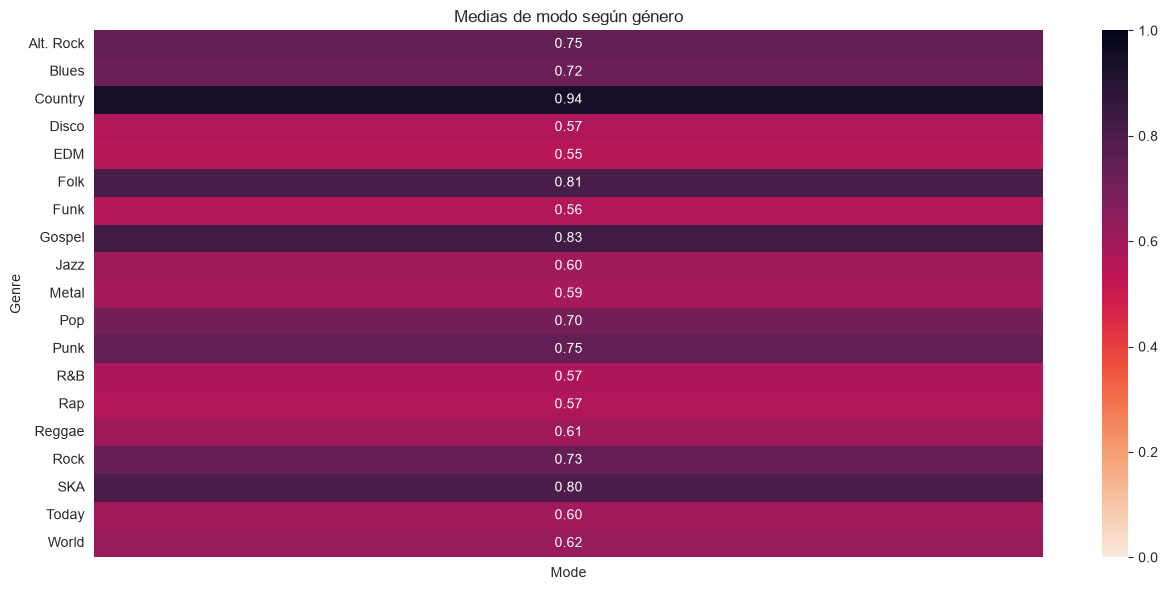

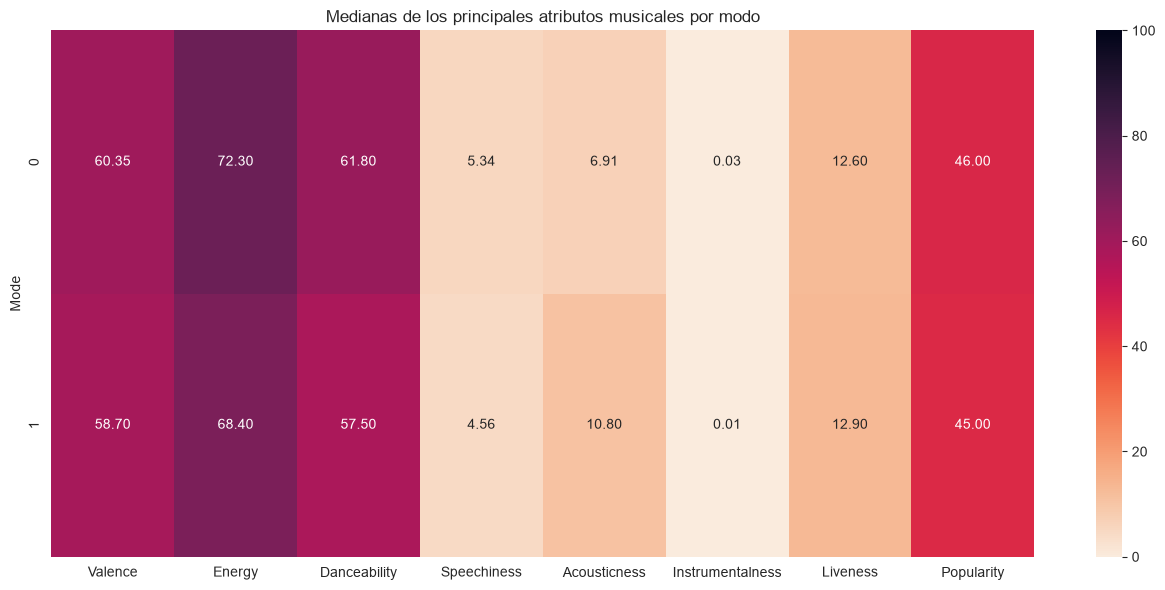

In [29]:
medianas(medianas1,"Medianas de los principales atributos musicales por género")
medianas(medianas2,"Medianas de los principales atributos musicales por tonalidad")
medianas(medianas3,"Medianas de los principales atributos musicales por compás")
mediasmodo(medianas4)
medianas(medianas5,"Medianas de los principales atributos musicales por modo")



# Matriz de correlaciones   

In [30]:
def matcorr(corr):
    

    plt.figure(figsize=(12, 5))

    sns.heatmap(
        corr,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        center=0,
        vmin =-1
    )

    plt.title("Matriz de correlaciones (Spearman) - Principales variables numéricas")
    plt.tight_layout()
    plt.show()
    return 
variablesmat = ["Year","Loudness","Valence","Energy","Acousticness","Danceability","Tempo","Instrumentalness","Speechiness","Popularity"]
corr = df[variablesmat].corr("spearman")

Podemos observar una correlación positiva notable entre el año de lanzamiento y el volumen (*loudness*). Además, la variable año también presenta una correlación positiva considerable con la energía (*energy*) y correlaciones negativas con la valencia (*valence*) y la acústica (*acousticness*).

En cuanto a la popularidad (*popularity*), las correlaciones son más débiles. Aun así, podemos destacar una relación positiva con el año de lanzamiento y el volumen, así como una correlación negativa con la instrumentalidad (*instrumentalness*).

Por último, también encontramos relaciones destacables entre otros atributos musicales. La acústica y la energía presentan una correlación negativa, mientras que el volumen y la energía muestran una correlación positiva. Asimismo, la valencia y la capacidad de baile (*danceability*) están positivamente correlacionadas.

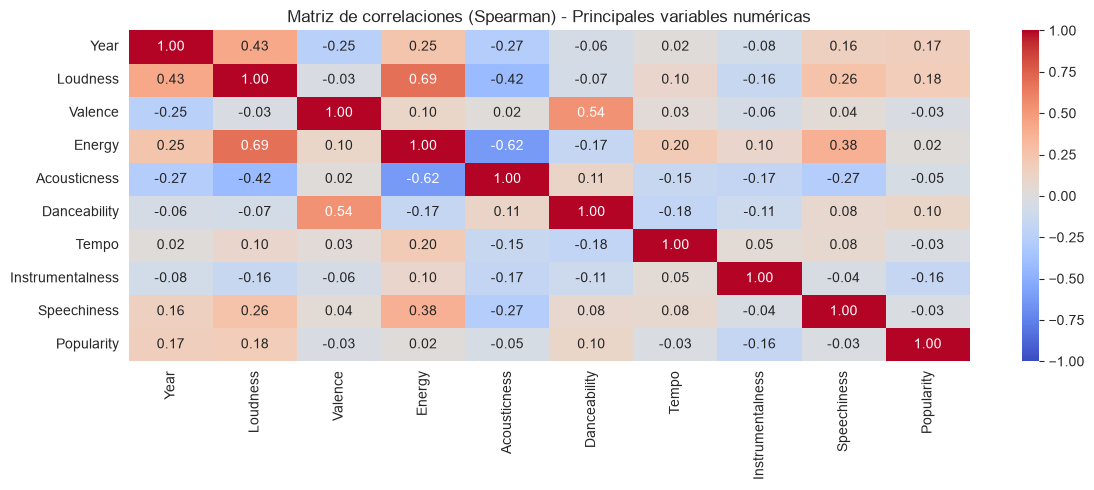

In [31]:

matcorr(corr)

# Evolución del volumen percivido

In [32]:
def graflin(df,y,titulo):
    plt.figure(figsize=(12,5))
    sns.lineplot(data = df, x = "Year" , y = y , hue = "Genre2", palette = "colorblind", estimator="mean", errorbar=("ci", 90))
    plt.title(titulo)
    plt.tight_layout()
    plt.show()
    return
def cajatemp(df, x,titulo):
    plt.figure(figsize=(12,5))

    sns.boxplot(data = df, x = x, y= "Genre2" , fill = True   ,hue = "Yearcat",showmeans=True,  meanprops={
            "marker": "o",
            "markerfacecolor": "black",
            "markeredgecolor": "black",
            "markersize": 7,
            "alpha": 0.6
        }
    )
    plt.title(titulo)
    plt.legend(
        title="Rango temporal",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        borderaxespad=0
        )
    plt.show()
    return

def densi(df,x,titulo):
    #plt.style.use("dark_background")

    plt.figure(figsize=(12,5))

    sns.kdeplot(data= df,x = x, hue="Year", palette=  "viridis", legend=False, common_norm=False,alpha = 0.6)
    plt.title(titulo)
    plt.show()

    return

En la categoría de todos los géneros el volumen medio de las canciones pasa de estar algo por encima a -12 dB en 1970 a estar cerca de -6db en el año 2015.
Una tendencia similar se obseva tanto con el Metal como con el Pop/Today. El gráfico de lineas nos permite obsevar como éste crecimento se da sobre todo entre 1990 y mediados de los 2000.

El gráfico de cajas nos permite observar estos tiempos. Entre la decada de los 70 y los 80 se obserban pocos cambios.

En los 90 el volumen mediano del metal, todos los génreos y del pop es ligeramente superior al de el resto de décadas.

Es en el siglo 21 cuando podemos observar 

Es  en

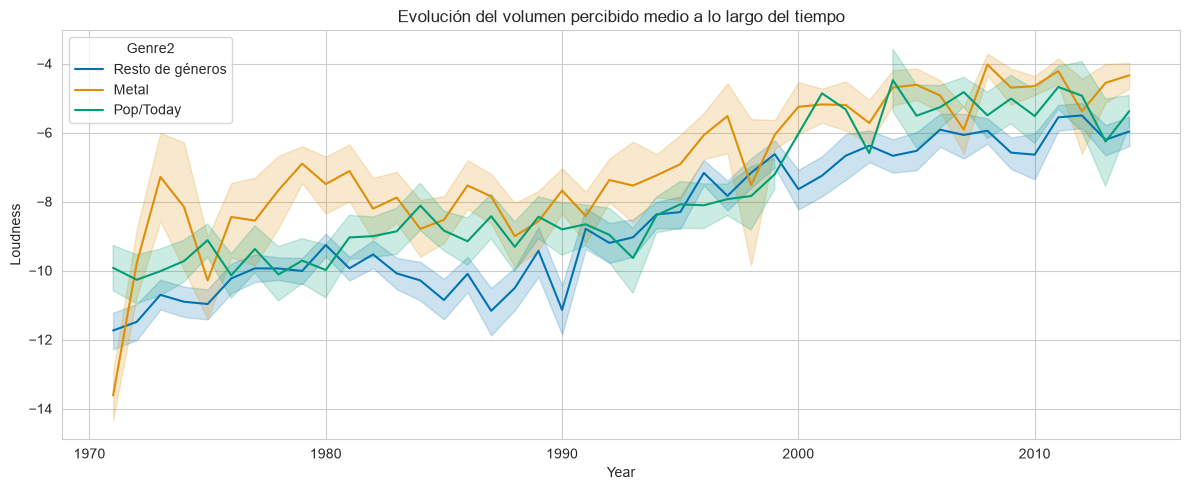

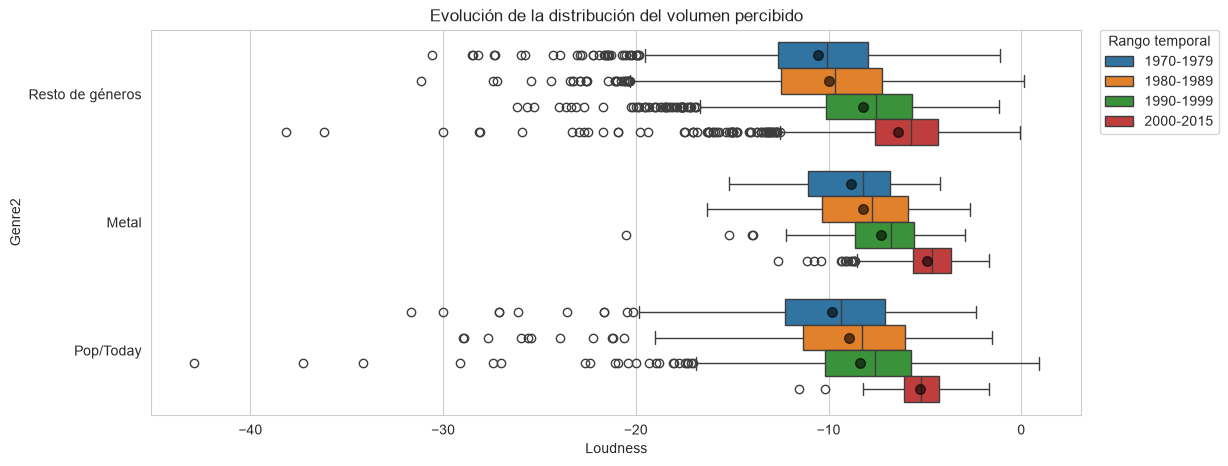

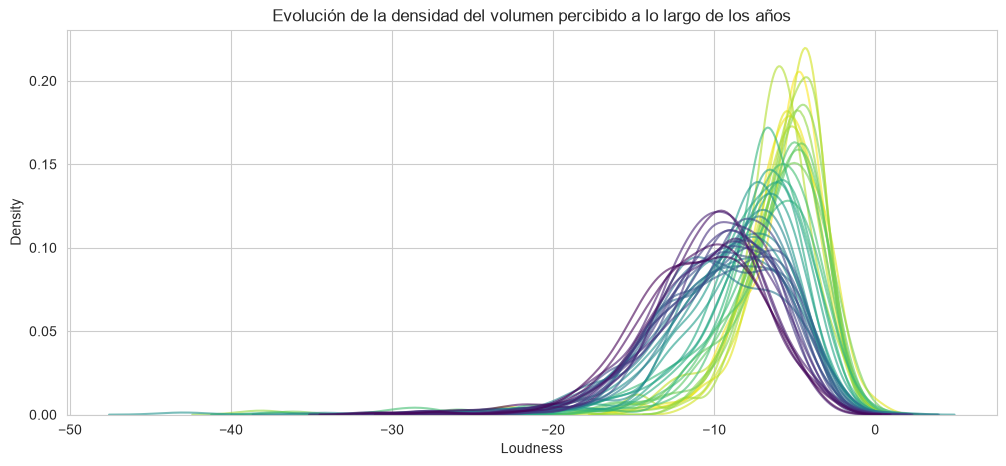

In [35]:
graflin(df,"Loudness","Evolución del volumen percibido medio a lo largo del tiempo")
cajatemp(df, "Loudness" ,"Evolución de la distribución del volumen percibido")
densi(df,"Loudness","Evolución de la densidad del volumen percibido a lo largo de los años")

# Evolución de la postividad

In [36]:
def graflin2(df):
    plt.figure(figsize=(12,5))

    sns.lineplot(
        data=df,
        x="Year",
        y="Valence",
        hue="Genre3",
        palette="colorblind",
        estimator="mean",
        errorbar=("ci", 90)
    )

    plt.xlim(1996, 2010)

    plt.title(
        "Evolución de la  positividad percibida por Spotify a lo largo de los años. "
        "Ciclo de guerra de Irak: Country vs resto de géneros"
    )

    plt.axvline(x=2001, color="red", linestyle="--", linewidth=0.5)
    plt.axhline(y=35, color="black", linestyle="--", linewidth=0.6)
    plt.axhline(y=76, color="black", linestyle="--", linewidth=0.6)

    plt.tight_layout()
    plt.show()
    return

    


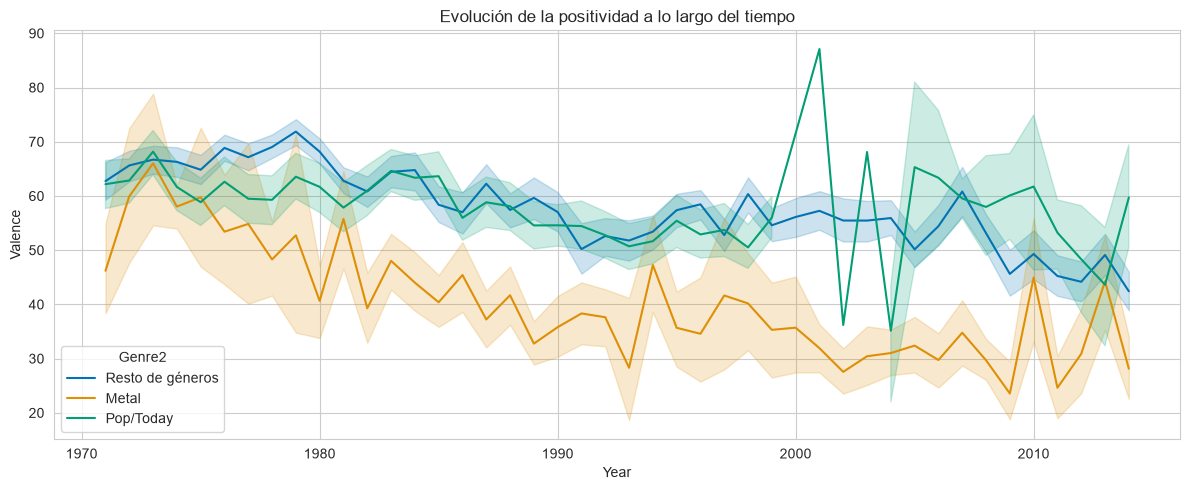

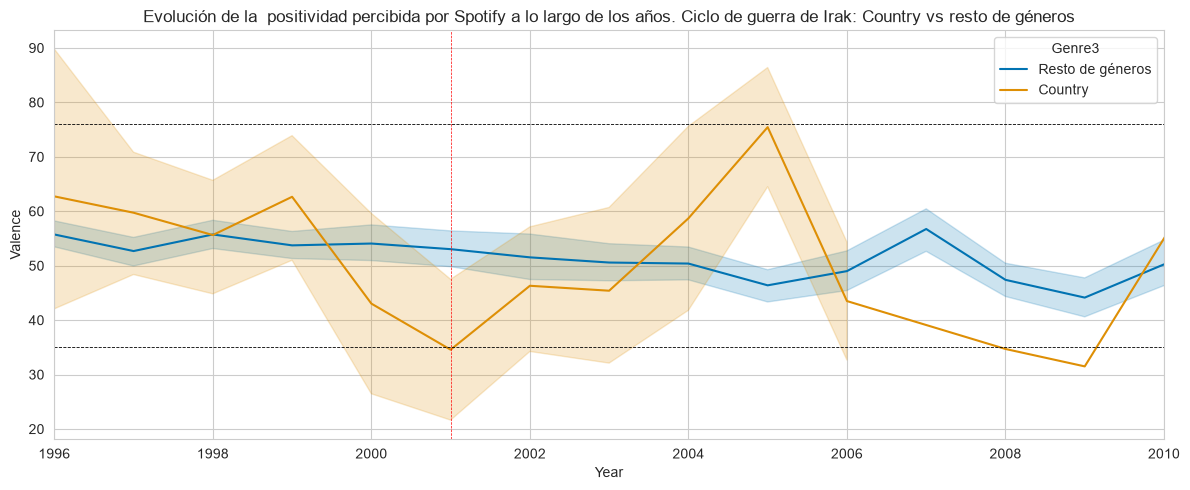

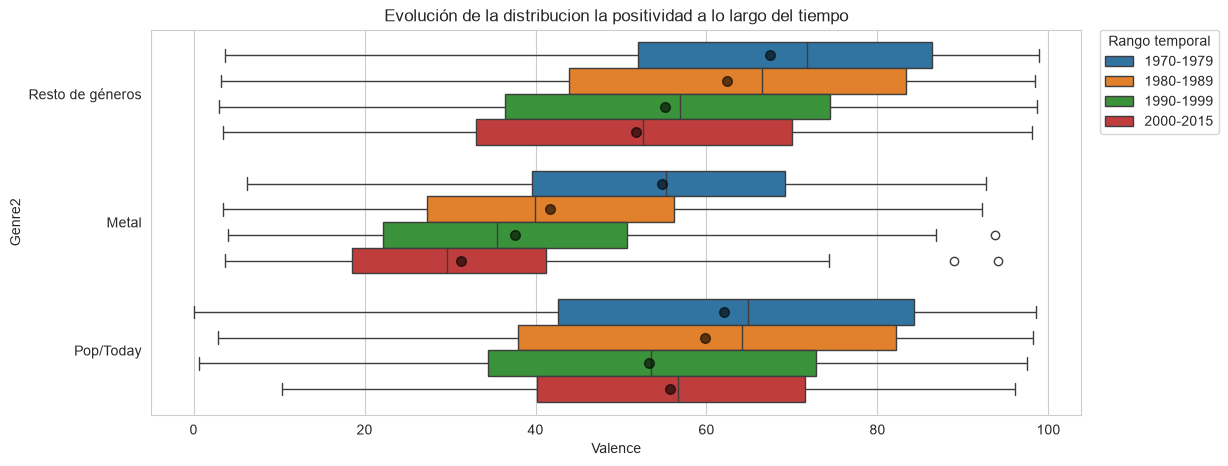

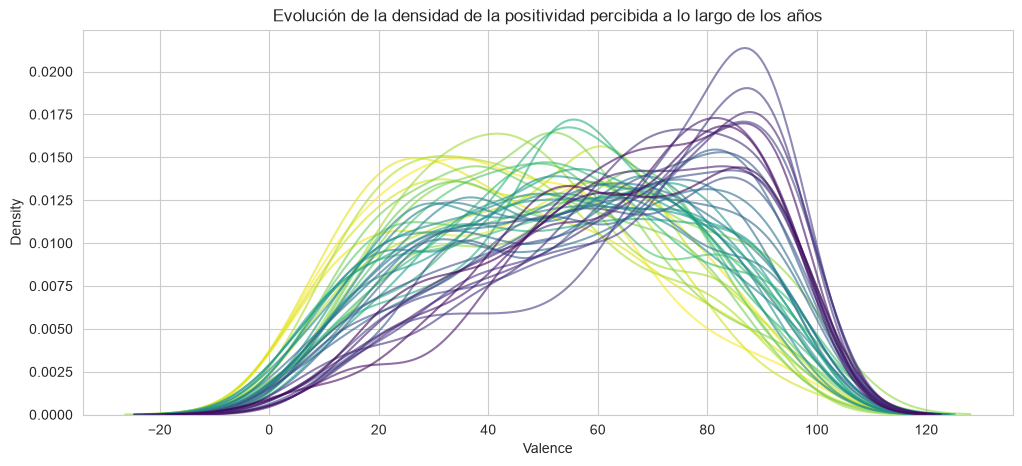

In [37]:
graflin(df,"Valence","Evolución de la positividad a lo largo del tiempo")
graflin2(df)
cajatemp(df, "Valence", "Evolución de la distribucion la positividad a lo largo del tiempo")
densi(df,"Valence","Evolución de la densidad de la positividad percibida a lo largo de los años")

# Evolución de la Energía

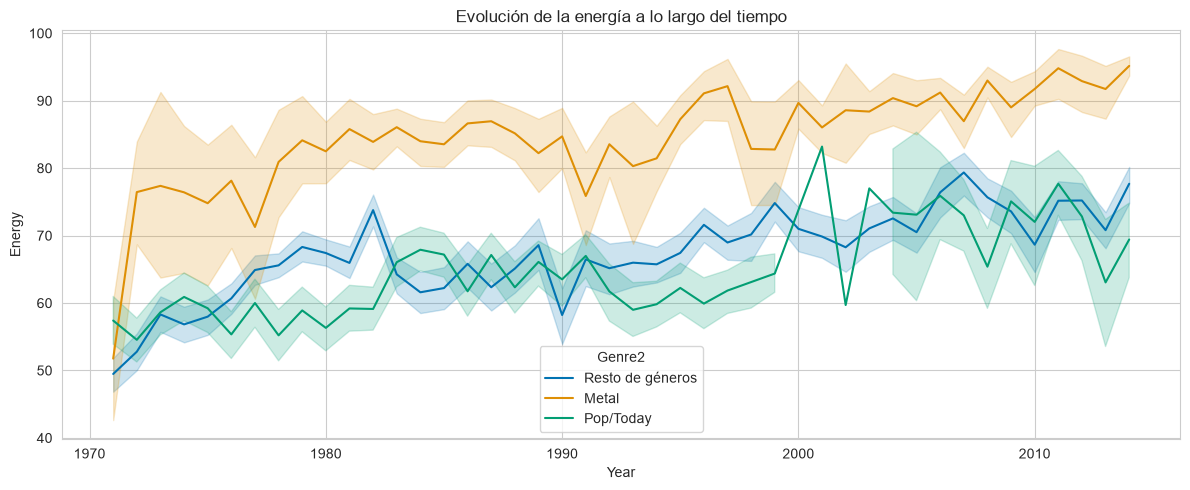

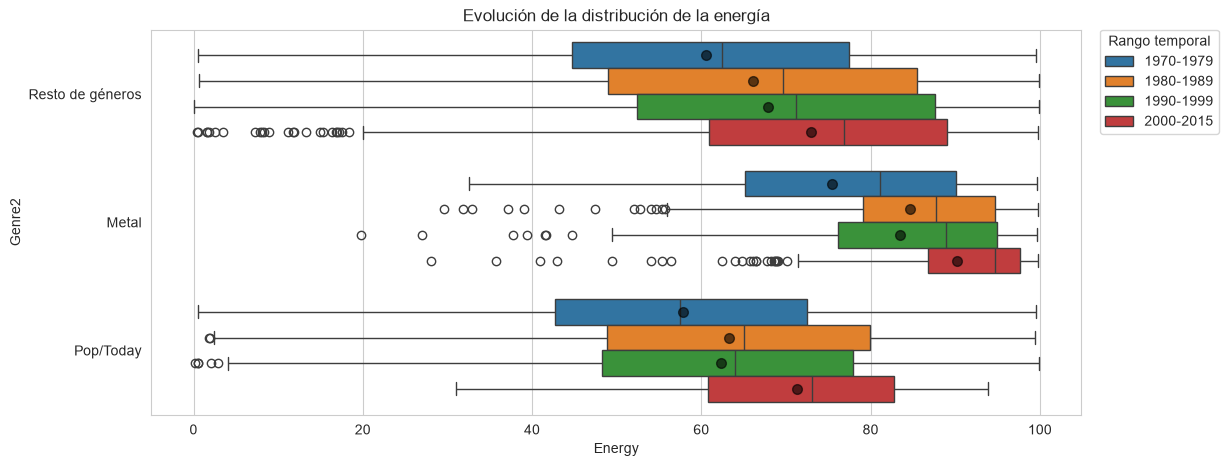

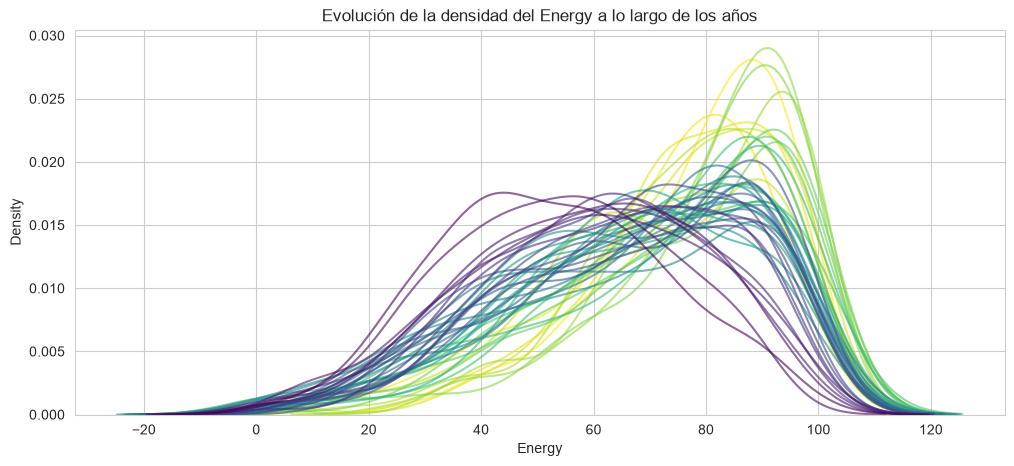

In [ ]:
graflin(df,"Energy","Evolución de la energía a lo largo del tiempo")
cajatemp(df, "Energy", "Evolución de la distribución de la energía")
densi(df,"Energy","Evolución de la densidad de la  energía  a lo largo de los años")

# ¿ Qué hace que una canción sea porpualr?
Para medir esta relación se vuelve a usar la correlación de Spearman.
Calculamos las correlaciones por cada genero entre atributo y popularidad.
Finalmente nos quedamos únicamente con aquellos valores con un p valor inferior al 0.01 y gráficamos con barras

In [40]:
def popugen(df, x):

    resultados = []

    for genero, subset in df.groupby("Genre"):
        r, p = spearmanr(subset[x], subset["Popularity"])

        if p < 0.01:
            resultados.append((genero, r, p))

    corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
    corr_df = corr_df.sort_values("R", ascending=False)

    plt.figure(figsize=(11, 4))

    sns.barplot(
        data=corr_df,
        x="R",
        y="Género",
        hue="R",
        palette="RdYlGn",
        hue_norm=(-1, 1),
        dodge=False,
        legend=False
    )

    plt.axvline(0, color="black", linewidth=0.8)
    plt.xlim(-1, 1)
    plt.title(f"Correlación entre  popularidad y {x}  por género (p < 0.01)")
    plt.tight_layout()
    plt.xlabel("Correlación Spearman")
    plt.show()
    return


Sí tenemos en cuenta la variable año, se evidenica  como cuanto más actual es una canción, esta es mas poipular en el caso del Rock alternativo, Gospel, Rap, Country, R&B, Reagge, Punk, Metal y Pop (de más relación a menos.) En el caso del Rock, cuanto más antigua es una canción esta es mas popular.


En cuanto a la Positivdad vemos como este atributo correlaciona de manera positiva  con la popularidad en el caso del EDM, Metal y Punk. Lo hace de manera negativa el rock alternatvo y el gospel. El metal y el EDM destacan por tener un nivel de Valence bajo. En este caso las canciones con una ligera diferencia a la tendencia parecen ser mas popular. 


Hemos encontrado una correlación postiva entre energía y popularidad en los casos de Country, Reagge, Rock alternativo y Pop. Por el contrario hemos encontrado correlaciópon negativa en los casos de Funk y EDM.Llama la atención el caso el EDM, ya que tiene un nivel de energía alto.

En cuanto la acusticidad encontramos otro fénomeno interesante. En el caso del Funk y del EDM cuanto más acustica es una canción, mas popular resulta. Esto es altamante llamativo, ya que el EDM es uno de menos acusticos del dataset. En el caso del pop, rock alternativo, country, blues y gospel hemos podido advertir una correlación negativa entre acusticdad y poplularidad. Esta lectura resulta mas interesante tendiendo en cuenta que tanto el Blues como el Gospel tienen unos niveles moderados de acusticidad.


El penúltimo parametro en el que nos vamos a fijar en este sector es el de la bailabilidad. En este sentido se han detectado únicamente correlaciones positivas entre el aspecto y la popularidad. Los géneros en los que la asociación entre variables ha resultado significativa son: Música actual, Jazz, Metal, Punk y EDM. En este segmento nos llaman la atención tanto el Metal como el Punk, que en el analsisi de medianas resultaron ser los géneros con nivel de bailablidad más bajos.

El últmo parametro que vamos a explicar es el de la instrumentalidad. En este aspecto se han encontrado varios génros que correlacionan negativamente entre esta cualidad y la popularidad: Estos en orden de intensdiad son: Jazz, EDM, Metal, Rock alternativo, Disco, Punk y Pop.
Si observamos de nuevo las medianas una vez multiplicadas por 100, solo hay dos géneros con un nivel mediano de instrumentalidad superior al 1, por un lado el EDM() y sobretodo Jazz(). Así que parece que el Jazz que se disntigue del resto de Jazz con algo menos de instrumentalidad es mas popular.


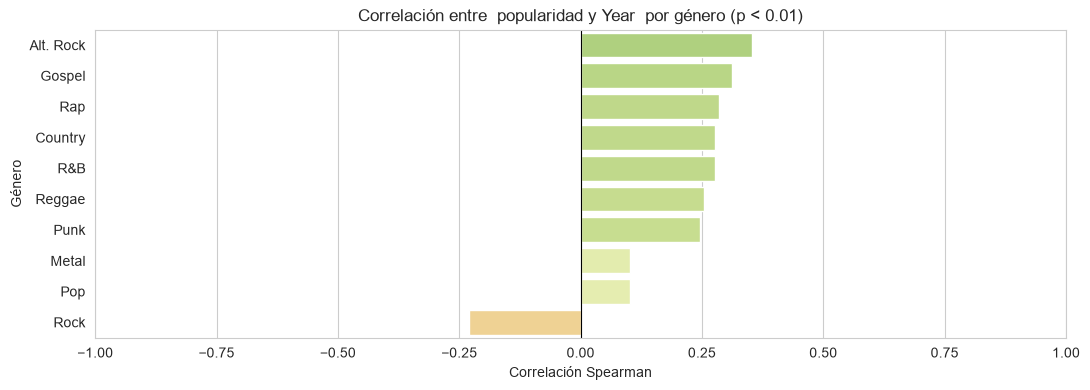

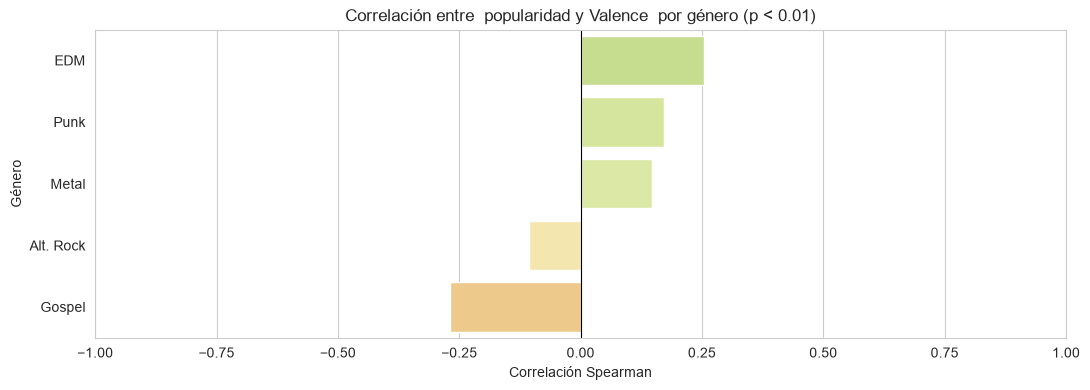

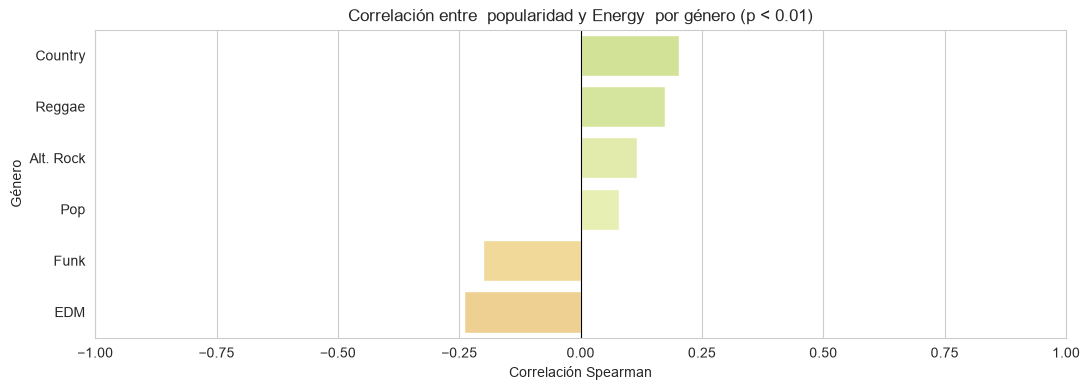

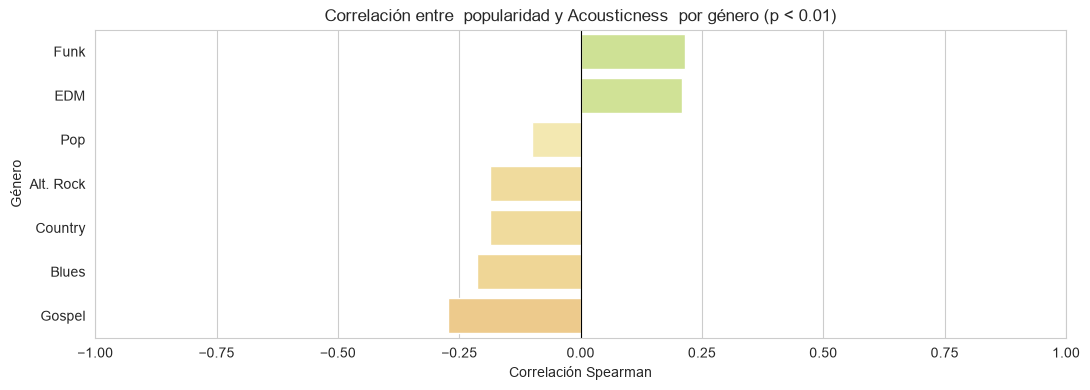

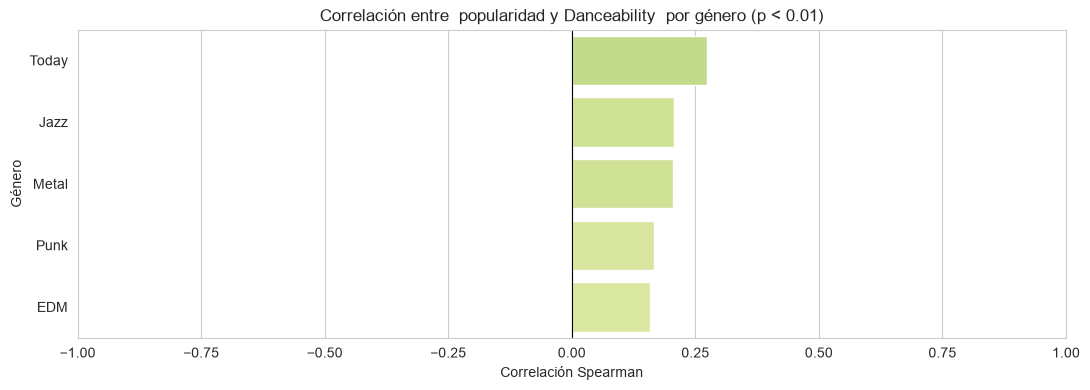

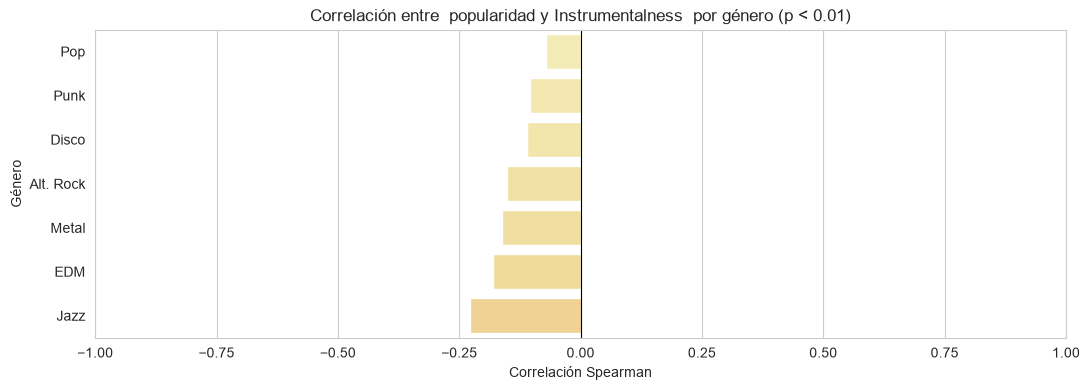

KeyError: 'Speachiness'

In [ ]:
popugen(df,"Year")
popugen(df,"Valence")
popugen(df,"Energy")
popugen(df,"Acousticness")
popugen(df,"Danceability")
popugen(df,"Instrumentalness")
